# Explaining link predictions

## ExamplE

[Paper](https://ceur-ws.org/Vol-4318/paper1.pdf) · [AmpliGraph, branch `paper/ISWC2026-XAI-KG-ExamplE`](https://github.com/Accenture/AmpliGraph/tree/paper/ISWC2026-XAI-KG-ExamplE)

In [12]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
import tensorflow as tf
from ampligraph.datasets import load_fb15k_237
from ampligraph.latent_features import ScoringBasedEmbeddingModel
from ampligraph.explanations import ExamplE

dataset = load_fb15k_237(return_mapper=True)

model = ScoringBasedEmbeddingModel(eta=5, k=300, scoring_type='TransE')
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.005), loss='self_adversarial')
model.fit(dataset['train'], batch_size=10000, epochs=10, verbose=0)
model.calibrate(dataset['test'], batch_size=500, positive_base_rate=0.8, epochs=1, verbose=False)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  4.20it/s]


In [28]:
[(i,x) for i,x in enumerate(dataset['test']) if 'influenced' in x[1]]

[(26,
  array(['/m/01xwqn', '/influence/influence_node/influenced_by',
         '/m/0121rx'], dtype=object)),
 (90,
  array(['/m/03g5jw', '/influence/influence_node/influenced_by',
         '/m/014_lq'], dtype=object)),
 (101,
  array(['/m/03j0d', '/influence/influence_node/influenced_by', '/m/03hnd'],
        dtype=object)),
 (322,
  array(['/m/019vgs', '/influence/influence_node/influenced_by',
         '/m/014zfs'], dtype=object)),
 (646,
  array(['/m/0b1zz', '/influence/influence_node/influenced_by', '/m/05xq9'],
        dtype=object)),
 (680,
  array(['/m/0jt90f5', '/influence/influence_node/influenced_by',
         '/m/019gz'], dtype=object)),
 (771,
  array(['/m/01d494', '/influence/influence_node/influenced_by', '/m/0dzkq'],
        dtype=object)),
 (832,
  array(['/m/0jbp0', '/influence/influence_node/influenced_by', '/m/0byfz'],
        dtype=object)),
 (925,
  array(['/m/0484q', '/influence/influence_node/influenced_by', '/m/073bb'],
        dtype=object)),
 (1029,
  array([

In [44]:
explainer = ExamplE(dataset, model)
tt = dataset['test'][1353]
print(names.get(tt[0], tt[0]), tt[1], names.get(tt[2], tt[2]))
explanation = explainer.predict_explain(tt)
print(explanation['prediction'], explanation['probability'])

names = dataset['mapper']
for e in explanation['examples']:
    print(names.get(e[0], e[0]), e[1], names.get(e[2], e[2]))

Eddie Murphy /influence/influence_node/influenced_by Jerry Lewis


/Users/adri/Work/Evergreen-Projects/nodes/AmpliGraph/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/adri/Work/Evergreen-Projects/nodes/AmpliGraph/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/adri/Work/Evergreen-Projects/nodes/AmpliGraph/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/adri/Work/Evergreen-Projects/nodes/AmpliGraph/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/adri/Work/Evergreen-Projects/nodes/AmpliGraph/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/adri/Work/Evergreen-Projects/nodes/AmpliGraph/.venv/lib/python3.12/site-packages/

[-2.0132556] [0.52957016]
Jim Carrey /influence/influence_node/influenced_by Jerry Lewis
Jim Carrey /influence/influence_node/influenced_by Mel Brooks


## Kelpie

[Paper](https://www.vldb.org/pvldb/vol15/p3566-rossi.pdf) · [Code](https://github.com/AndRossi/Kelpie) · requires an NVIDIA GPU (CUDA)

In [4]:
%%bash
set -e
[ -d methods/Kelpie ] || git clone https://github.com/AndRossi/Kelpie.git methods/Kelpie
cd methods/Kelpie
pip install -q numpy tqdm matplotlib torch reportlab
mkdir -p ../cuda_shim stored_models

# shim: ignore CUDA calls when there is no GPU
cat > ../cuda_shim/sitecustomize.py <<'EOF'
import torch
if not torch.cuda.is_available():
    def _d(a):
        if isinstance(a, torch.device) and a.type == 'cuda': return torch.device('cpu')
        if isinstance(a, str) and a.startswith('cuda'): return 'cpu'
        return a
    _t, _m = torch.Tensor.to, torch.nn.Module.to
    torch.Tensor.to = lambda s, *a, **k: _t(s, *[_d(x) for x in a], **{n: _d(v) for n, v in k.items()})
    torch.nn.Module.to = lambda s, *a, **k: _m(s, *[_d(x) for x in a], **{n: _d(v) for n, v in k.items()})
    torch.Tensor.cuda = lambda s, *a, **k: s
    torch.nn.Module.cuda = lambda s, *a, **k: s
    torch.cuda.get_rng_state = lambda *a, **k: torch.get_rng_state()
    torch.cuda.set_rng_state = lambda *a, **k: None
    torch.cuda.manual_seed = lambda *a, **k: None
    torch.cuda.manual_seed_all = lambda *a, **k: None
EOF
export PYTHONPATH=../cuda_shim

# train TransE on WN18 (README hyperparameters, fewer epochs)
python3 scripts/transe/train.py --dataset WN18 --max_epochs 50 --batch_size 2048 --learning_rate 0.0002 --dimension 50 --negative_samples_ratio 5 --regularizer_weight 0 --margin 2

# explain one prediction
head -1 input_facts/transe_wn18_random.csv > one_fact.csv
python3 scripts/transe/explain.py --dataset WN18 --max_epochs 200 --batch_size 2048 --learning_rate 0.01 --dimension 50 --negative_samples_ratio 5 --regularizer_weight 0 --margin 2 --model_path stored_models/TransE_WN18.pt --facts_to_explain_path one_fact.csv --mode necessary

cat output.txt


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
train loss: : 284672ex [00:00, 346674.76ex/s, loss=1.983667]                          
train loss: : 284672ex [00:00, 436375.13ex/s, loss=1.962592]                          
train loss: : 284672ex [00:00, 428300.26ex/s, loss=1.886938]                          
train loss: : 284672ex [00:00, 424777.72ex/s, loss=1.868315]                          
train loss: : 284672ex [00:00, 430877.86ex/s, loss=1.878096]                          
train loss: : 284672ex [00:00, 436665.11ex/s, loss=1.677453]                          
train loss: : 284672ex [00:00, 423593.84ex/s, loss=1.692464]                          
train loss: : 284672ex [00:00, 413283.24ex/s, loss=1.733626]                          
train loss: : 284672ex [00:00, 426858.04ex/s, loss=1.680815]                          
train loss: : 284672ex [00:00, 418120.10ex/s, loss=1.62506]                           
train loss: : 28467

	 saving model...
	 done.
Evaluating model...
	Test Hits@1: 0.057600
	Test Hits@10: 0.149400
	Test Mean Reciprocal Rank: 0.089525
	Test Mean Rank: 5821.251100
Loading dataset WN18...
Reading facts to explain...
Explaining fact 0 on 1: <05395690,_has_part,05508943>
Extracting promising facts for<05395690, _has_part, 05508943>
	Analyzing sample 1 on 20: <05395690, _hyponym, 02399942>
	Analyzing sample 2 on 20: <02733187, _derivationally_related_form, 05395690>
	Analyzing sample 3 on 20: <05367912, _part_of, 05395690>
	Analyzing sample 4 on 20: <05508943, _part_of, 05395690>
	Analyzing sample 5 on 20: <05298729, _hyponym, 05395690>
	Analyzing sample 6 on 20: <02399424, _hypernym, 05395690>
	Analyzing sample 7 on 20: <05395690, _derivationally_related_form, 02733187>
	Analyzing sample 8 on 20: <05395690, _hyponym, 02399424>
	Analyzing sample 9 on 20: <05395690, _has_part, 05345581>
	Analyzing sample 10 on 20: <05395690, _has_part, 05367735>
	Analyzing sample 11 on 20: <05395690, _hypernym,

## GNNExplainer

[Paper](https://arxiv.org/abs/1903.03894) · [PyTorch Geometric](https://pytorch-geometric.readthedocs.io/en/latest/modules/explain.html)

```bash
pip install torch torch_geometric scikit-learn matplotlib
```

In [5]:
import os.path as osp

import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

import torch_geometric.transforms as T
from torch_geometric.datasets import Planetoid
from torch_geometric.explain import Explainer, GNNExplainer, ModelConfig
from torch_geometric.nn import GCNConv

if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')


class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def encode(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        x = self.conv2(x, edge_index)
        return x

    def decode(self, z, edge_label_index):
        src, dst = edge_label_index
        return (z[src] * z[dst]).sum(dim=-1)

    def forward(self, x, edge_index, edge_label_index):
        z = self.encode(x, edge_index)
        return self.decode(z, edge_label_index).view(-1)

/Users/adri/Work/Evergreen-Projects/nodes/AmpliGraph/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/adri/Work/Evergreen-Projects/nodes/AmpliGraph/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [6]:
def train_model(dataset, train_data, val_data, test_data):

    model = GCN(dataset.num_features, 128, 64).to(device)
    optimizer = torch.optim.Adam(params=model.parameters(), lr=0.01)

    def train():
        model.train()
        optimizer.zero_grad()

        out = model(train_data.x, train_data.edge_index,
                    train_data.edge_label_index)
        loss = F.binary_cross_entropy_with_logits(out, train_data.edge_label)
        loss.backward()
        optimizer.step()
        return float(loss)

    @torch.no_grad()
    def test(data):
        model.eval()
        out = model(data.x, data.edge_index, data.edge_label_index).sigmoid()
        return roc_auc_score(data.edge_label.cpu().numpy(), out.cpu().numpy())

    for epoch in range(1, 201):
        loss = train()
        if epoch % 20 == 0:
            val_auc = test(val_data)
            print(f'Epoch: {epoch:02d}, Loss: {loss:.4f}, Val: {val_auc:.4f}, ')

    model_config = ModelConfig(
        mode='binary_classification',
        task_level='edge',
        return_type='raw',
    )
    return model, model_config

In [7]:
path = osp.join('.', 'data', 'Planetoid')
transform = T.Compose([
    T.NormalizeFeatures(),
    T.ToDevice(device),
    T.RandomLinkSplit(num_val=0.05, num_test=0.1, is_undirected=True),
])
dataset = Planetoid(path, 'CiteSeer', transform=transform)
train_data, val_data, test_data = dataset[0]

model, model_config = train_model(dataset, train_data, val_data, test_data)

edge_label_index = val_data.edge_label_index[:, 0]

explainer = Explainer(
    model=model,
    explanation_type='model',
    algorithm=GNNExplainer(epochs=200),
    node_mask_type='attributes',
    edge_mask_type='object',
    model_config=model_config,
)
explanation = explainer(
    x=train_data.x,
    edge_index=train_data.edge_index,
    edge_label_index=edge_label_index,
)
explanation.visualize_graph('explain.png')

/var/folders/_0/jv6cjgz56m70w9v_33cyrcn00000gn/T/ipykernel_19482/4063971948.py:15: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  return float(loss)


Epoch: 20, Loss: 0.4823, Val: 0.7852, 
Epoch: 40, Loss: 0.3071, Val: 0.8018, 
Epoch: 60, Loss: 0.1623, Val: 0.7723, 
Epoch: 80, Loss: 0.0632, Val: 0.7498, 
Epoch: 100, Loss: 0.0172, Val: 0.7248, 
Epoch: 120, Loss: 0.0049, Val: 0.7276, 
Epoch: 140, Loss: 0.0015, Val: 0.7227, 
Epoch: 160, Loss: 0.0007, Val: 0.7247, 
Epoch: 180, Loss: 0.0004, Val: 0.7235, 
Epoch: 200, Loss: 0.0003, Val: 0.7253, 


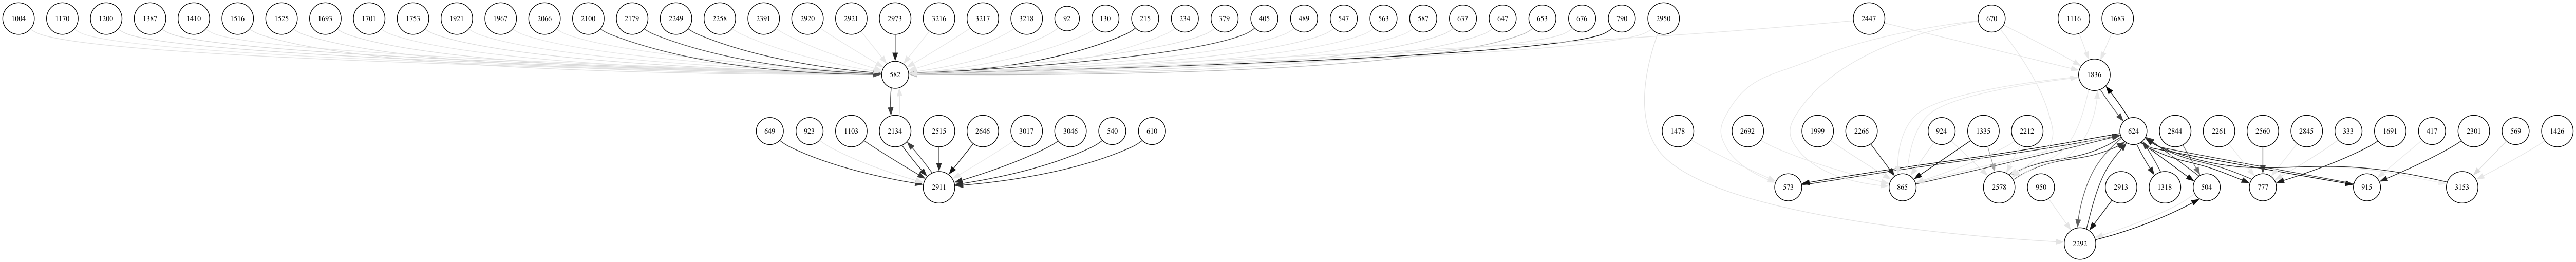

In [8]:
from IPython.display import Image
Image('explain.png')

## Gradient Rollback

[Paper](https://arxiv.org/abs/2010.05516) · [Code](https://github.com/carolinlawrence/gradient-rollback)